# 04 - HAM10000 classifier on `real_sq256` (arms A0-A2 first, A3 later)

**Purpose:** One classifier notebook for every arm of the class-imbalance study, so that the real-only baselines and the GAN arm
share exactly the same input, pipeline, budget and model-selection rule.

**Update from previous version (`02_HAM10000_baseline_A0-A2.ipynb`):** real images are read from `real_sq256/` (256x256 centre-square crops from `01_prepare_gan_data`, the same format as the GAN images), and arm A3 (A2 + GAN images) is added. All other settings are unchanged.

| Arm | Imbalance strategy | Training data | Loss | Sampler |
|---|---|---|---|---|
| A0_ce | none | real train | cross-entropy | uniform |
| A1_weighted_ce | loss re-weighting | real train | inverse-frequency weighted CE (real train counts) | uniform |
| A2_oversample | re-sampling | real train | cross-entropy | class-balanced `WeightedRandomSampler` |
| A3_gan_topup | re-sampling + synthetic top-up | real train + GAN images of `SYN_CLASSES` | cross-entropy | class-balanced (same rule as A2) |

**Protocol:**
1. The split is loaded from `HAM10000_lesion_split_seed42_v2.csv` and checked against its canonical SHA-256 fingerprint.
2. `real_sq256` is checked against `prep_info.json`, and the GAN training list (`gan_train_manifest.csv`) must equal the v2 train split.
3. Synthetic images (A3 only) are added to the train split only, validation and test are real images only. Images flagged by the memorization check are excluded.
4. Model selection uses validation only, the test split is evaluated once per run.
5. A3 settings (`SYN_VERSION`, `SYN_EXPECTED_SNAPSHOT`, `SYN_CLASSES`, `SYN_PER_REAL`) must be fixed and recorded before the first A3 run.

**Kaggle setup:** Accelerator: GPU T4 x1.
Finished runs are skipped, so the notebook can be re-run after a timeout (`RESUME_FROM`).

In [ ]:
CFG = dict(
    IMAGE_ROOT="/kaggle/input",            # searched recursively for the manifest, real_sq256/, prep_info.json, synthetic sets
    MANIFEST_PATH=None,                    # None = search IMAGE_ROOT for the file name below
    MANIFEST_NAME="HAM10000_lesion_split_seed42_v2.csv",
    EXPECTED_SHA256="bda53d198ff403653548b8f072116e78350067417ddf41ec3e342f034bf464d7",  # canonical v2 fingerprint
    REAL_DIR_NAME="real_sq256",            # folder from notebook 01 (images named <image_id>.png)
    IMG_RES=256,                           # expected size of real_sq256 and GAN images
    OUT_DIR="/kaggle/working/classifier_sq256",
    RESUME_FROM=None,                      # e.g. "/kaggle/input/<previous-output>/classifier_sq256"

    BACKBONE="resnet50",                   # keep fixed for every arm
    PRETRAINED=True,
    IMG_SIZE=224,                          # network input: crop 224 from the 256x256 image

    EPOCHS=15,
    PATIENCE=5,
    BATCH_SIZE=64,
    LR=1e-4,
    WEIGHT_DECAY=1e-4,
    AMP=True,

#    ARMS=["A0_ce", "A1_weighted_ce", "A2_oversample"],   # later: ["A3_gan_topup"]
    ARMS=["A3_gan_topup"],
    TRAIN_SEEDS=[1, 2, 3],
    N_BOOTSTRAP=1000,
    NUM_WORKERS=2,
    SAVE_CHECKPOINTS=False,

    # ---- A3 only (ignored when no A3 arm is listed). ----
    SYN_VERSION="synthetic_v2",            # VERSION folder written by notebook 03
    SYN_EXPECTED_SNAPSHOT="network-snapshot-003320.pkl",            # e.g. "network-snapshot-001000.pkl" = the kimg locked in protocol
    SYN_CLASSES=["akiec", "df", "vasc"],   # minority classes topped up (same as MINORITY in notebook 03)
    SYN_PER_REAL=1.0,                      # synthetic images per real training image of that class (1.0 = double the class)

    DRY_RUN=False,                         # True = tiny smoke test (few images, 1 epoch, no pretrained weights)
)
CFG

{'IMAGE_ROOT': '/kaggle/input',
 'MANIFEST_PATH': None,
 'MANIFEST_NAME': 'HAM10000_lesion_split_seed42_v2.csv',
 'EXPECTED_SHA256': 'bda53d198ff403653548b8f072116e78350067417ddf41ec3e342f034bf464d7',
 'REAL_DIR_NAME': 'real_sq256',
 'IMG_RES': 256,
 'OUT_DIR': '/kaggle/working/classifier_sq256',
 'RESUME_FROM': None,
 'BACKBONE': 'resnet50',
 'PRETRAINED': True,
 'IMG_SIZE': 224,
 'EPOCHS': 15,
 'PATIENCE': 5,
 'BATCH_SIZE': 64,
 'LR': 0.0001,
 'WEIGHT_DECAY': 0.0001,
 'AMP': True,
 'ARMS': ['A3_gan_topup'],
 'TRAIN_SEEDS': [1, 2, 3],
 'N_BOOTSTRAP': 1000,
 'NUM_WORKERS': 2,
 'SAVE_CHECKPOINTS': False,
 'SYN_VERSION': 'synthetic_v2',
 'SYN_EXPECTED_SNAPSHOT': 'network-snapshot-003320.pkl',
 'SYN_CLASSES': ['akiec', 'df', 'vasc'],
 'SYN_PER_REAL': 1.0,
 'DRY_RUN': False}

## 1. Environment

In [2]:
import os, sys, json, time, glob, hashlib, random, platform, copy
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision
from torchvision import transforms
import sklearn
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_recall_fscore_support, confusion_matrix, roc_auc_score)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path(CFG["OUT_DIR"]); (OUT / "runs").mkdir(parents=True, exist_ok=True)

# Continue from a previous Kaggle version: copy its finished runs (those with metrics.json) into OUT_DIR
if CFG["RESUME_FROM"]:
    import shutil
    prev = sorted(Path(CFG["RESUME_FROM"]).glob("runs/*/metrics.json"))
    for m in prev:
        dst = OUT / "runs" / m.parent.name
        if not dst.exists():
            shutil.copytree(m.parent, dst)
    print(f"resume: {len(prev)} finished runs found in {CFG['RESUME_FROM']}")

ENV = {
    "python": sys.version.split()[0], "torch": torch.__version__, "torchvision": torchvision.__version__,
    "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__,
    "platform": platform.platform(), "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}
print(json.dumps(ENV, indent=2))
if DEVICE.type != "cuda" and not CFG["DRY_RUN"]:
    print("WARNING: no GPU found. Turn on a GPU accelerator before a full run.")

{
  "python": "3.13.15",
  "torch": "2.11.0+cu128",
  "torchvision": "0.26.0+cu128",
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "sklearn": "1.6.1",
  "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
  "device": "cuda",
  "gpu": "Tesla T4"
}


## 2. Load and verify the frozen split manifest

`manifest_fingerprint` hashes the 4 columns sorted by `image_id` (UTF-8 CSV, header, `\n` line endings), so it does not depend on
row order or file encoding. If the check fails, the file is not the frozen v2 manifest -> stop. Do not edit `EXPECTED_SHA256`.

In [3]:
def find_all(root, pattern):
    return sorted(glob.glob(os.path.join(root, "**", pattern), recursive=True))

def find_file(root, name):
    hits = find_all(root, name)
    if not hits:
        raise FileNotFoundError(f"{name} not found under {root}")
    if len(hits) > 1:
        print("Several copies found, using the first:", hits)
    return hits[0]

def manifest_fingerprint(df):
    cols = ["image_id", "lesion_id", "dx", "split"]
    canon = df[cols].sort_values("image_id").reset_index(drop=True)
    payload = canon.to_csv(index=False, lineterminator="\n").encode("utf-8")
    return hashlib.sha256(payload).hexdigest()

manifest_path = CFG["MANIFEST_PATH"] or find_file(CFG["IMAGE_ROOT"], CFG["MANIFEST_NAME"])
manifest = pd.read_csv(manifest_path)
print("manifest:", manifest_path, manifest.shape)

need = {"image_id", "lesion_id", "dx", "split"}
assert need <= set(manifest.columns), f"manifest must contain {need}, has {list(manifest.columns)}"

fp = manifest_fingerprint(manifest)
print("fingerprint:", fp)
if fp != CFG["EXPECTED_SHA256"]:
    raise RuntimeError(
        "Manifest fingerprint does not match EXPECTED_SHA256.\n"
        "The manifest file is not the frozen v2 manifest (or it was edited). Stop and investigate.")

assert manifest["image_id"].is_unique, "duplicate image_id"
assert set(manifest["split"]) == {"train", "val", "test"}, set(manifest["split"])
assert manifest.groupby("lesion_id")["split"].nunique().max() == 1, "a lesion appears in more than one split"
assert manifest.groupby("lesion_id")["dx"].nunique().max() == 1, "a lesion has more than one label"
L = {s: set(manifest.loc[manifest.split == s, "lesion_id"]) for s in ["train", "val", "test"]}
overlap = {f"{a}∩{b}": len(L[a] & L[b]) for a, b in [("train", "val"), ("train", "test"), ("val", "test")]}
print("lesion overlap:", overlap)
assert sum(overlap.values()) == 0

CLASSES = sorted(manifest["dx"].unique())
assert len(CLASSES) == 7, CLASSES
CIDX = {c: i for i, c in enumerate(CLASSES)}
manifest["y"] = manifest["dx"].map(CIDX)

counts = pd.crosstab(manifest["split"], manifest["dx"]).loc[["train", "val", "test"], CLASSES]
counts["images"] = counts.sum(axis=1)
counts["lesions"] = manifest.groupby("split")["lesion_id"].nunique()
display(counts)

manifest: /kaggle/input/datasets/bumkum/dsr301m/HAM10000_lesion_split_seed42_v2.csv (10015, 4)
fingerprint: bda53d198ff403653548b8f072116e78350067417ddf41ec3e342f034bf464d7
lesion overlap: {'train∩val': 0, 'train∩test': 0, 'val∩test': 0}


dx,akiec,bcc,bkl,df,mel,nv,vasc,images,lesions
split,,,,,,,,,
train,222,361,772,71,773,4683,99,6981,5229
val,53,82,160,24,173,1018,22,1532,1120
test,52,71,167,20,167,1004,21,1502,1121


## 3. Real images from `real_sq256/` (notebook 01): checks and cache

Checks: `prep_info.json` says 256 px centre-square crops of all 10,015 images, the GAN training list from notebook 01
(`gan_train_manifest.csv`) contains exactly the v2 train split, every manifest image has a PNG in `real_sq256/`.

In [4]:
real_dirs = [d for d in find_all(CFG["IMAGE_ROOT"], CFG["REAL_DIR_NAME"]) if os.path.isdir(d)]
assert real_dirs, f"No '{CFG['REAL_DIR_NAME']}' folder under {CFG['IMAGE_ROOT']} — add the output of notebook 01 as input."
if len(real_dirs) > 1:
    print("Several real_sq256 folders found, using the first:", real_dirs)
REAL_DIR = real_dirs[0]

PREP_INFO = json.load(open(find_file(CFG["IMAGE_ROOT"], "prep_info.json")))
print("real_sq256:", REAL_DIR)
print("prep_info:", {k: PREP_INFO.get(k) for k in ["created", "res", "crop", "resample", "format", "n_real_sq_images",
                                                   "n_gan_train_images", "gan_train_zip_sha256"]})
assert PREP_INFO["res"] == CFG["IMG_RES"] and PREP_INFO["crop"] == "center_square", "real_sq256 is not 256 px centre-square"
assert PREP_INFO["n_real_sq_images"] == len(manifest), (PREP_INFO["n_real_sq_images"], len(manifest))

gan_train_ids = set(pd.read_csv(find_file(CFG["IMAGE_ROOT"], "gan_train_manifest.csv"))["image_id"])
v2_train_ids = set(manifest.loc[manifest.split == "train", "image_id"])
print(f"GAN training list = v2 train split: {gan_train_ids == v2_train_ids} "
      f"({len(gan_train_ids)} vs {len(v2_train_ids)} images)")
assert gan_train_ids == v2_train_ids, "notebook 01 trained the GAN on a different image list than the v2 train split!"

paths = {Path(p).stem: p for p in glob.glob(os.path.join(REAL_DIR, "*.png"))}
missing = sorted(set(manifest["image_id"]) - set(paths))
print(f"found {len(paths)} PNG files in real_sq256; missing for manifest: {len(missing)}")

if CFG["DRY_RUN"]:
    keep = manifest[manifest["image_id"].isin(paths)]
    manifest = keep.groupby(["split", "dx"]).head(6).reset_index(drop=True)
    CFG.update(EPOCHS=1, PRETRAINED=False, TRAIN_SEEDS=[1], N_BOOTSTRAP=50, BATCH_SIZE=16, NUM_WORKERS=0)
    print("DRY_RUN: using", len(manifest), "images")
else:
    assert not missing, f"{len(missing)} manifest images not found, e.g. {missing[:5]}"

def load_png(path):
    with Image.open(path) as im:
        a = np.asarray(im.convert("RGB"), dtype=np.uint8)
    assert a.shape == (CFG["IMG_RES"], CFG["IMG_RES"], 3), (path, a.shape)
    return a

t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as ex:
    arrays = list(ex.map(load_png, [paths[i] for i in manifest["image_id"]]))
CACHE = dict(zip(manifest["image_id"], arrays))
print(f"cached {len(CACHE)} real images, {sum(a.nbytes for a in arrays) / 1e6:.0f} MB, {time.time() - t0:.0f}s")

real_sq256: /kaggle/input/notebooks/kietvgpham/01-prepare-gan-data/real_sq256
prep_info: {'created': '2026-10-19 10:32:06', 'res': 256, 'crop': 'center_square', 'resample': 'LANCZOS', 'format': 'PNG', 'n_real_sq_images': 10015, 'n_gan_train_images': 6981, 'gan_train_zip_sha256': '488306f8cee3a96de0f888049990778ab7a915dfd93433521180d19a565aa6df'}
GAN training list = v2 train split: True (6981 vs 6981 images)
found 10015 PNG files in real_sq256; missing for manifest: 0
cached 10015 real images, 1969 MB, 79s


## 4. Synthetic images (A3 only)

Loaded only when an `A3…` arm is listed. The set is identified by its `VERSION` folder (`generator_info.json`), and must come from a
generator trained on this very `gan_train.zip`. Per class in `SYN_CLASSES`, the first `round(SYN_PER_REAL x n_real_train)` images
in seed order that were not flagged by the memorization check are used (a deterministic rule fixed before training).

In [ ]:
A3_ARMS = [a for a in CFG["ARMS"] if a.startswith("A3")]
SYN, SYN_INFO = None, None
if A3_ARMS:
    infos = [p for p in find_all(CFG["IMAGE_ROOT"], "generator_info.json")
             if json.load(open(p)).get("version") == CFG["SYN_VERSION"]]
    assert len(infos) == 1, f"need exactly one synthetic set with version '{CFG['SYN_VERSION']}', found {infos}"
    syn_dir = Path(infos[0]).parent
    SYN_INFO = json.load(open(infos[0]))
    print("synthetic set:", syn_dir, "| snapshot:", SYN_INFO["generator_snapshot"],
          "| kimg:", SYN_INFO["generator_total_kimg"], "| cuda_ops:", SYN_INFO.get("cuda_ops"))
    assert SYN_INFO["gan_train_zip_sha256"] == PREP_INFO["gan_train_zip_sha256"], \
        "synthetic set was not generated by a GAN trained on this gan_train.zip"
    if CFG["SYN_EXPECTED_SNAPSHOT"]:
        assert SYN_INFO["generator_snapshot"] == CFG["SYN_EXPECTED_SNAPSHOT"], \
            (SYN_INFO["generator_snapshot"], CFG["SYN_EXPECTED_SNAPSHOT"])
    else:
        print("WARNING: SYN_EXPECTED_SNAPSHOT is None - set it to the snapshot locked in protocol v1.2.")

    sm = pd.read_csv(syn_dir / "synthetic_manifest.csv")
    assert (sm["split"] == "train").all() and (sm["source"] == "gan").all()
    sm["flag_memorized"] = sm["flag_memorized"].astype(str).str.lower().eq("true")
    print("flagged as memorized (excluded):", sm.groupby("dx")["flag_memorized"].sum().to_dict())
    sm = sm[~sm["flag_memorized"]]
    real_train = manifest[manifest.split == "train"]
    picks = []
    for c in CFG["SYN_CLASSES"]:
        n_real = int((real_train["dx"] == c).sum())
        n_take = int(round(CFG["SYN_PER_REAL"] * n_real))
        avail = sm[sm["dx"] == c].sort_values("seed")
        assert len(avail) >= n_take, f"{c}: need {n_take} unflagged synthetic images, only {len(avail)}"
        picks.append(avail.head(n_take))
        print(f"  {c:6s} real train {n_real:4d} → synthetic used {n_take:4d} (available {len(avail)})")
    SYN = pd.concat(picks).reset_index(drop=True)
    SYN = SYN.assign(lesion_id=SYN["image_id"], split="train", y=SYN["dx"].map(CIDX))
    with ThreadPoolExecutor(max_workers=8) as ex:
        syn_arrays = list(ex.map(load_png, [str(syn_dir / p) for p in SYN["path"]]))
    CACHE.update(zip(SYN["image_id"], syn_arrays))
    SYN[["image_id", "dx", "seed", "generator_snapshot", "nn_sim"]].to_csv(OUT / f"synthetic_used_{CFG['SYN_VERSION']}.csv",
                                                                          index=False)
    print(f"cached {len(SYN)} synthetic images")
else:
    print("No A3 arm listed - synthetic images not loaded.")

synthetic set: /kaggle/input/notebooks/bumkum/03-generate-and-qc-fid-v2/synthetic_v2 | snapshot: network-snapshot-003320.pkl | kimg: 3320 | cuda_ops: None
flagged as memorized (excluded): {'akiec': 6, 'df': 1, 'vasc': 0}
  akiec  real train  222 → synthetic used  222 (available 794)
  df     real train   71 → synthetic used   71 (available 599)
  vasc   real train   99 → synthetic used   99 (available 600)
cached 392 synthetic images


## 5. Data pipeline

Train: random resized crop to 224 (scale 0.6-1.0), horizontal/vertical flips, rotation +-20 degree, mild colour jitter.  
Validation/test: centre crop 224 of the 256x256 image. ImageNet normalisation. Same transforms for real and synthetic images.

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
TF_TRAIN = transforms.Compose([
    transforms.RandomResizedCrop(CFG["IMG_SIZE"], scale=(0.6, 1.0), ratio=(3 / 4, 4 / 3)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.1, 0.1, 0.1, 0.02),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
TF_EVAL = transforms.Compose([
    transforms.CenterCrop(CFG["IMG_SIZE"]),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])

class HamDataset(Dataset):
    def __init__(self, df, tf):
        self.ids, self.y, self.tf = df["image_id"].tolist(), df["y"].to_numpy(), tf
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        return self.tf(Image.fromarray(CACHE[self.ids[i]])), int(self.y[i])

DF = {s: manifest[manifest["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
train_counts = np.bincount(DF["train"]["y"], minlength=len(CLASSES))
print("real train counts:", dict(zip(CLASSES, train_counts.tolist())))

# A1: inverse-frequency weights from the REAL train split, scaled so the average weight per training image is 1
CLASS_WEIGHTS = train_counts.sum() / (len(CLASSES) * np.maximum(train_counts, 1))
print("A1 class weights:", dict(zip(CLASSES, np.round(CLASS_WEIGHTS, 3).tolist())))

def train_df_for(arm):
    if arm.startswith("A3"):
        cols = ["image_id", "lesion_id", "dx", "y"]
        return pd.concat([DF["train"][cols], SYN[cols]], ignore_index=True)
    return DF["train"]

if A3_ARMS:
    a3 = train_df_for(A3_ARMS[0])
    print("A3 train counts (real + synthetic):", a3["dx"].value_counts().reindex(CLASSES).to_dict())

real train counts: {'akiec': 222, 'bcc': 361, 'bkl': 772, 'df': 71, 'mel': 773, 'nv': 4683, 'vasc': 99}
A1 class weights: {'akiec': 4.492, 'bcc': 2.763, 'bkl': 1.292, 'df': 14.046, 'mel': 1.29, 'nv': 0.213, 'vasc': 10.074}
A3 train counts (real + synthetic): {'akiec': 444, 'bcc': 361, 'bkl': 772, 'df': 142, 'mel': 773, 'nv': 4683, 'vasc': 198}


## 6. Model, training and evaluation functions

In [ ]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def build_model():
    name = CFG["BACKBONE"]
    if name == "resnet50":
        w = torchvision.models.ResNet50_Weights.IMAGENET1K_V2 if CFG["PRETRAINED"] else None
        m = torchvision.models.resnet50(weights=w)
        m.fc = nn.Linear(m.fc.in_features, len(CLASSES))
    elif name == "efficientnet_b0":
        w = torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1 if CFG["PRETRAINED"] else None
        m = torchvision.models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, len(CLASSES))
    else:
        raise ValueError(name)
    return m.to(DEVICE)

def make_loader(df, arm, seed, train):
    ds = HamDataset(df, TF_TRAIN if train else TF_EVAL)
    g = torch.Generator(); g.manual_seed(seed)
    kw = dict(batch_size=CFG["BATCH_SIZE"], num_workers=CFG["NUM_WORKERS"], worker_init_fn=seed_worker,
              generator=g, pin_memory=DEVICE.type == "cuda", persistent_workers=CFG["NUM_WORKERS"] > 0)
    if train and (arm == "A2_oversample" or arm.startswith("A3")):
        # class-balanced sampling: every class gets the same expected share; counts taken from THIS training set
        cnt = np.bincount(df["y"], minlength=len(CLASSES))
        w = (1.0 / np.maximum(cnt, 1))[df["y"].to_numpy()]
        sampler = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), num_samples=len(ds),
                                        replacement=True, generator=g)
        return DataLoader(ds, sampler=sampler, drop_last=True, **kw)
    return DataLoader(ds, shuffle=train, drop_last=train, **kw)

@torch.no_grad()
def predict(model, loader):
    model.eval(); probs, ys, loss_sum = [], [], 0.0
    ce = nn.CrossEntropyLoss(reduction="sum")
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=CFG["AMP"] and DEVICE.type == "cuda"):
            logits = model(x)
        loss_sum += ce(logits.float(), y).item()
        probs.append(torch.softmax(logits.float(), 1).cpu().numpy()); ys.append(y.cpu().numpy())
    probs, ys = np.concatenate(probs), np.concatenate(ys)
    return probs, ys, loss_sum / len(ys)

def metrics(y, prob):
    pred = prob.argmax(1); K = len(CLASSES)
    p, r, f, s = precision_recall_fscore_support(y, pred, labels=range(K), zero_division=0)
    out = {
        "n": int(len(y)),
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),   # = macro recall
        "macro_f1": f1_score(y, pred, labels=range(K), average="macro", zero_division=0),
        "weighted_f1": f1_score(y, pred, labels=range(K), average="weighted", zero_division=0),
        "per_class": {c: {"precision": p[i], "recall": r[i], "f1": f[i], "support": int(s[i])} for i, c in enumerate(CLASSES)},
        "confusion_matrix": confusion_matrix(y, pred, labels=range(K)).tolist(),  # rows = true, cols = predicted
    }
    try:
        out["macro_ovr_auroc"] = roc_auc_score(y, prob, multi_class="ovr", average="macro", labels=range(K))
    except ValueError:
        out["macro_ovr_auroc"] = None
    return out

def _macro_f1_bacc(y, pred, K):
    cm = np.bincount(y * K + pred, minlength=K * K).reshape(K, K)
    tp = np.diag(cm); support = cm.sum(1); predicted = cm.sum(0)
    rec = np.divide(tp, support, out=np.zeros(K), where=support > 0)
    prec = np.divide(tp, predicted, out=np.zeros(K), where=predicted > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros(K), where=(prec + rec) > 0)
    present = support > 0
    return f1[present].mean(), rec[present].mean()

def lesion_bootstrap(y, pred, lesion_ids, n, seed=0):
    # Resample LESIONS with replacement (images of one lesion stay together) -> 95% percentile CI
    rng = np.random.default_rng(seed); K = len(CLASSES)
    groups = pd.Series(np.arange(len(y))).groupby(np.asarray(lesion_ids)).apply(np.array).tolist()
    f1s, baccs = [], []
    for _ in range(n):
        idx = np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])
        f, b = _macro_f1_bacc(y[idx], pred[idx], K); f1s.append(f); baccs.append(b)
    q = lambda a: [float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))]
    return {"macro_f1_ci95": q(f1s), "balanced_accuracy_ci95": q(baccs), "n_resamples": n, "n_lesions": len(groups)}

In [8]:
def to_jsonable(o):
    if isinstance(o, dict): return {k: to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o

def save_predictions(path, split, prob, y):
    d = DF[split][["image_id", "lesion_id", "dx"]].copy()
    d["y_true"] = y; d["y_pred"] = prob.argmax(1)
    for i, c in enumerate(CLASSES): d[f"p_{c}"] = prob[:, i]
    d.to_csv(path, index=False)

def run_label(arm):
    # A3 runs are named after the synthetic set, so G0 and G1 sets (H2) never overwrite each other
    return f"{arm}-{CFG['SYN_VERSION']}" if arm.startswith("A3") else arm

def run(arm, seed):
    label = run_label(arm)
    rdir = OUT / "runs" / f"{label}_seed{seed}"
    if (rdir / "metrics.json").exists():
        print(f"skip {rdir.name} (already done)"); return
    rdir.mkdir(parents=True, exist_ok=True)
    set_seed(seed)
    model = build_model()
    weight = torch.tensor(CLASS_WEIGHTS, dtype=torch.float32, device=DEVICE) if arm == "A1_weighted_ce" else None
    criterion = nn.CrossEntropyLoss(weight=weight)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["EPOCHS"])
    scaler = torch.amp.GradScaler(enabled=CFG["AMP"] and DEVICE.type == "cuda")
    tr_df = train_df_for(arm)
    tr = make_loader(tr_df, arm, seed, train=True)
    va = make_loader(DF["val"], arm, seed, train=False)

    log, best, best_state, bad = [], -1.0, None, 0
    for ep in range(1, CFG["EPOCHS"] + 1):
        model.train(); t0 = time.time(); tot, n = 0.0, 0
        for x, y in tr:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=CFG["AMP"] and DEVICE.type == "cuda"):
                loss = criterion(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(y); n += len(y)
        sched.step()
        pv, yv, vloss = predict(model, va); mv = metrics(yv, pv)
        row = {"epoch": ep, "lr": opt.param_groups[0]["lr"], "train_loss": tot / max(n, 1), "val_loss": vloss,
               "val_macro_f1": mv["macro_f1"], "val_balanced_accuracy": mv["balanced_accuracy"],
               "val_accuracy": mv["accuracy"], "seconds": time.time() - t0}
        log.append(row); pd.DataFrame(log).to_csv(rdir / "epoch_log.csv", index=False)
        print(f"{label} s{seed} ep{ep:02d} train_loss {row['train_loss']:.4f} val_loss {vloss:.4f} "
              f"val_macroF1 {mv['macro_f1']:.4f} val_bacc {mv['balanced_accuracy']:.4f} ({row['seconds']:.0f}s)")
        if mv["macro_f1"] > best:
            best, bad, best_ep = mv["macro_f1"], 0, ep
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["PATIENCE"]:
                print("early stop"); break

    model.load_state_dict(best_state)
    pv, yv, _ = predict(model, va); save_predictions(rdir / "pred_val.csv", "val", pv, yv)
    pt, yt, tloss = predict(model, make_loader(DF["test"], arm, seed, train=False))   # test: evaluated once
    save_predictions(rdir / "pred_test.csv", "test", pt, yt)
    res = {
        "arm": label, "base_arm": arm, "seed": seed, "best_epoch": best_ep, "epochs_run": len(log),
        "n_train_images": int(len(tr_df)), "train_counts": tr_df["dx"].value_counts().reindex(CLASSES).fillna(0).astype(int).to_dict(),
        "val": metrics(yv, pv), "test": metrics(yt, pt), "test_loss": tloss,
        "test_bootstrap": lesion_bootstrap(yt, pt.argmax(1), DF["test"]["lesion_id"].to_numpy(), CFG["N_BOOTSTRAP"]),
        "config": CFG, "env": ENV, "manifest_sha256": fp, "classes": CLASSES,
        "image_source": {"real_dir": REAL_DIR, "prep_info": PREP_INFO},
        "synthetic": ({"version": CFG["SYN_VERSION"], "generator_info": SYN_INFO,
                       "n_used": SYN["dx"].value_counts().to_dict()} if arm.startswith("A3") else None),
        "class_weights": CLASS_WEIGHTS.tolist() if arm == "A1_weighted_ce" else None,
    }
    if CFG["SAVE_CHECKPOINTS"]:
        torch.save(best_state, rdir / "best.pt")
    (rdir / "metrics.json").write_text(json.dumps(to_jsonable(res), indent=2))
    t = res["test"]
    print(f"==> {label} s{seed} TEST macroF1 {t['macro_f1']:.4f} bacc {t['balanced_accuracy']:.4f} acc {t['accuracy']:.4f}")
    del model; torch.cuda.empty_cache() if DEVICE.type == "cuda" else None

## 7. Run all arms x seeds (finished runs are skipped)

In [9]:
(OUT / "config.json").write_text(json.dumps(to_jsonable({
    "config": CFG, "env": ENV, "manifest": manifest_path, "manifest_sha256": fp, "classes": CLASSES,
    "real_dir": REAL_DIR, "prep_info": PREP_INFO, "synthetic_info": SYN_INFO}), indent=2))
for seed in CFG["TRAIN_SEEDS"]:
    for arm in CFG["ARMS"]:
        run(arm, seed)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 236MB/s]


A3_gan_topup-synthetic_v2 s1 ep01 train_loss 1.0274 val_loss 0.7863 val_macroF1 0.5575 val_bacc 0.5999 (35s)
A3_gan_topup-synthetic_v2 s1 ep02 train_loss 0.4147 val_loss 0.8653 val_macroF1 0.6048 val_bacc 0.6405 (35s)
A3_gan_topup-synthetic_v2 s1 ep03 train_loss 0.3100 val_loss 0.8262 val_macroF1 0.6341 val_bacc 0.6682 (34s)
A3_gan_topup-synthetic_v2 s1 ep04 train_loss 0.2483 val_loss 0.6865 val_macroF1 0.6367 val_bacc 0.6704 (34s)
A3_gan_topup-synthetic_v2 s1 ep05 train_loss 0.2067 val_loss 0.6623 val_macroF1 0.6524 val_bacc 0.6461 (34s)
A3_gan_topup-synthetic_v2 s1 ep06 train_loss 0.1644 val_loss 0.6731 val_macroF1 0.6243 val_bacc 0.6180 (34s)
A3_gan_topup-synthetic_v2 s1 ep07 train_loss 0.1449 val_loss 0.6217 val_macroF1 0.6557 val_bacc 0.6322 (34s)
A3_gan_topup-synthetic_v2 s1 ep08 train_loss 0.1172 val_loss 0.6346 val_macroF1 0.6648 val_bacc 0.6570 (35s)
A3_gan_topup-synthetic_v2 s1 ep09 train_loss 0.0978 val_loss 0.6435 val_macroF1 0.6784 val_bacc 0.6707 (34s)
A3_gan_topup-synthe

## 8. Summary across seeds

Means +- SD over training seeds, 95% CIs are lesion-level bootstrap intervals per run (test split).  
Rare classes rest on few independent lesions in the test split, so their per-class recall is noisy.

In [10]:
ARM_ORDER = ["A0_ce", "A1_weighted_ce", "A2_oversample"]
rows = []
for f in sorted((OUT / "runs").glob("*/metrics.json")):
    r = json.loads(f.read_text()); t = r["test"]
    row = {"arm": r["arm"], "seed": r["seed"], "best_epoch": r["best_epoch"],
           "test_macro_f1": t["macro_f1"], "test_balanced_accuracy": t["balanced_accuracy"],
           "test_accuracy": t["accuracy"], "test_macro_ovr_auroc": t["macro_ovr_auroc"],
           "test_macro_f1_ci95": r["test_bootstrap"]["macro_f1_ci95"],
           "val_macro_f1": r["val"]["macro_f1"]}
    for c in CLASSES:
        row[f"recall_{c}"] = t["per_class"][c]["recall"]
    rows.append(row)
runs = pd.DataFrame(rows)
runs.to_csv(OUT / "summary_runs.csv", index=False)
display(runs.round(4))

order = [a for a in ARM_ORDER if a in set(runs["arm"])] + sorted(set(runs["arm"]) - set(ARM_ORDER))
num = [c for c in runs.columns if c not in ("arm", "seed", "test_macro_f1_ci95")]
agg = runs.groupby("arm")[num].agg(["mean", "std"])
agg.columns = [f"{a}_{b}" for a, b in agg.columns]
agg = agg.reindex(order)
agg.to_csv(OUT / "summary_by_arm.csv")
show = ["test_macro_f1", "test_balanced_accuracy", "test_accuracy", "val_macro_f1"] + [f"recall_{c}" for c in CLASSES]
display(pd.DataFrame({k: agg[f"{k}_mean"].map("{:.4f}".format) + " ± " + agg[f"{k}_std"].map("{:.4f}".format)
                      for k in show}).T)

,arm,seed,best_epoch,test_macro_f1,test_balanced_accuracy,test_accuracy,test_macro_ovr_auroc,test_macro_f1_ci95,val_macro_f1,recall_akiec,recall_bcc,recall_bkl,recall_df,recall_mel,recall_nv,recall_vasc
0,A3_gan_topup-synthetic_v2,1,11,0.7281,0.7043,0.8096,0.9633,"[0.673119105881585, 0.774402896214598]",0.6784,0.6346,0.7183,0.7844,0.65,0.5509,0.8775,0.7143
1,A3_gan_topup-synthetic_v2,2,14,0.6834,0.6846,0.7943,0.9502,"[0.6265309651461131, 0.7276543015507331]",0.6606,0.4231,0.7746,0.7904,0.55,0.6467,0.8456,0.7619
2,A3_gan_topup-synthetic_v2,3,7,0.7122,0.7262,0.7790,0.9562,"[0.659483816404694, 0.7526393632379728]",0.6592,0.5962,0.7606,0.7784,0.75,0.5629,0.8257,0.8095


arm,A3_gan_topup-synthetic_v2
test_macro_f1,0.7079 ± 0.0227
test_balanced_accuracy,0.7050 ± 0.0208
test_accuracy,0.7943 ± 0.0153
val_macro_f1,0.6661 ± 0.0107
recall_akiec,0.5513 ± 0.1127
recall_bcc,0.7512 ± 0.0293
recall_bkl,0.7844 ± 0.0060
recall_df,0.6500 ± 0.1000
recall_mel,0.5868 ± 0.0522
recall_nv,0.8496 ± 0.0261


## 9. Figures

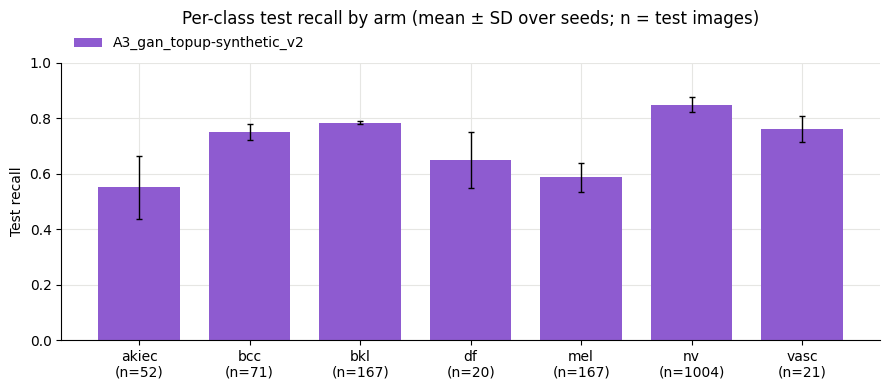

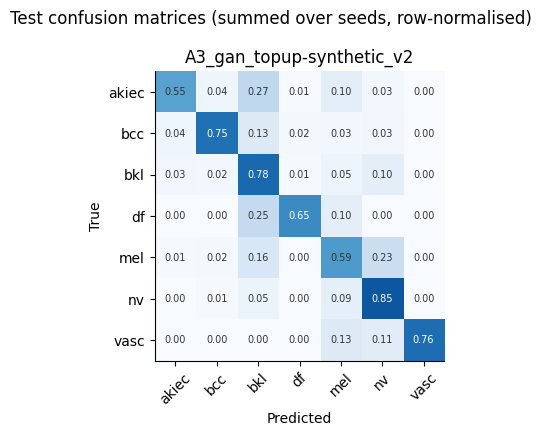

In [ ]:
import matplotlib.pyplot as plt
FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)
BASE_COLORS = {"A0": "#2a78d6", "A1": "#eb6834", "A2": "#1baf7a", "A3": "#8e5bd0"}   # fixed per arm family
color_of = lambda a: BASE_COLORS.get(a[:2], "#777777")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True})

# Per-class test recall: mean over seeds, error bars = SD
arms = order
x = np.arange(len(CLASSES)); w = 0.8 / max(len(arms), 1)
fig, ax = plt.subplots(figsize=(9, 4))
for k, a in enumerate(arms):
    sub = runs[runs["arm"] == a][[f"recall_{c}" for c in CLASSES]]
    ax.bar(x + (k - (len(arms) - 1) / 2) * w, sub.mean(), w * 0.92, yerr=sub.std().fillna(0),
           color=color_of(a), label=a, capsize=2, error_kw={"elinewidth": 1})
support = DF["test"]["dx"].value_counts()
ax.set_xticks(x, [f"{c}\n(n={support.get(c, 0)})" for c in CLASSES])
ax.set_ylim(0, 1.0); ax.set_ylabel("Test recall")
ax.set_title("Per-class test recall by arm (mean ± SD over seeds; n = test images)", pad=28)
ax.legend(frameon=False, ncol=len(arms), loc="lower left", bbox_to_anchor=(0, 1.0))
fig.tight_layout(); fig.savefig(FIG / "per_class_recall.png", dpi=200); plt.show()

# Confusion matrices summed over seeds, row-normalised (share of each true class)
fig, axes = plt.subplots(1, len(arms), figsize=(4.6 * len(arms), 4.4), squeeze=False)
for ax, a in zip(axes[0], arms):
    cm = sum(np.array(json.loads(f.read_text())["test"]["confusion_matrix"])
             for f in (OUT / "runs").glob(f"{a}_seed*/metrics.json"))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cmn[i, j] > 0.6 else "#333333")
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45); ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(a)
fig.suptitle("Test confusion matrices (summed over seeds, row-normalised)")
fig.tight_layout(); fig.savefig(FIG / "confusion_matrices.png", dpi=200); plt.show()